## A/B Testing, Randomized Controlled Trials

- We want to estimate the **average treatment effect**: The average difference in outcomes between the treatment and control groups
- Remember, the stakes are something like: If we implement this intervention at the scale of millions of patients, how many lives are:
    - Saved because the treatment works and our experiment showed it did (Good)
    - Not lost because the treatment doesn't work and our experiment showed it doesn't work (Good)
    - Not saved because the treatment works but our experiment failed to show it did (Bad)
    - Lost because the treatment actually harms patients, but our experiment falsely suggested it works (Very bad)

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

We generally can't compare what would have happened to observation $i$, if they had been assigned to the other treatment. This means we only observe
$$
y_{iA} = \text{Outcome for $i$ receiving treatment $A$ }
$$
or
$$
y_{iB} = \text{Outcome for $i$ receiving treatment $B$ }
$$
but not both. The **average outcome** for group $A$ is
$$
\frac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA}
$$
and the **average outcome** for group $B$ is
$$
\frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}.
$$
When we difference them, we get the **Average Treatment Effect (ATE)**:
$$
ATE = \dfrac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA} \quad - \quad \frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}
$$
As long as treatment is randomly assigned, there is no reason to think that the participants in group $A$ or $B$ are systematically different, and the **ATE** is an unbiased estimator of the true contrast in outcomes between groups $B$ and $A$. We "average away" the differences across the two groups to get an estimate of the difference in outcomes.

We then use bootstrapping to do two things:

1. Estimate the density/distribution for the averages outcomes in both groups
2. Estimate the ATE and its density/distribution

## Part 1

- First, we're going to evaluate a particular clinical trial, on chronic kidney disease:
    - ISCHEMIA-Chronic Kidney Disease Trial (ISCHEMIA-CKD)
    - ClinicalTrials.gov ID NCT01985360
    - Sponsor NYU Langone Health
    - Information provided by NYU Langone Health (Responsible Party)
- The study compared a "routine invasive therapy" (intra-aortic balloon pumps) intended to reduce death/heart attack versus more conservative medical interventions during heart surgery

<div>
<img src="./src/ischemia.png" width="700"/>
</div>

**1.** Load the `./data/iabp.csv` data. Cross tabulate `Group` and `Survived`. What is the point estimate of the ATE? Would you rather get the intra aortic balloon pump or not? Remember, **Invasive** means pump and **Conservative** means not.

In [3]:
df = pd.read_csv('./data/iabp.csv')

## Crosstabs, average treatment effect:
print(pd.crosstab( df['Group'], df['Survived']), '\n')

ate = df.loc[ df['Group'] == 'Invasive', 'Survived'].mean() \
    - df.loc[ df['Group'] == 'Conservative', 'Survived'].mean() 
print('Estimated ATE: ', np.round(ate, 3))

Survived      0.0  1.0
Group                 
Conservative  291   98
Invasive      294   94 

Estimated ATE:  -0.01


98/389 = 0.2519 - conservative
94/388 = 0.242 - Invasive
I would rather not get the pump. This is due to the survival rate being slightly higher with the conservative group, but also because the idea does not thrill me.

**2.** Bootstrap the average outcome for group A, the average outcome for group B, and difference then to get the ATE, 10,000 times. Store all of these estimates. This is important: **Bootstrap the two groups separately, since this is a clinical trial and there was random assignment (we want to maintain the balance across treatment arms because that maximizes statistical power)**.

In [4]:
## Bootstrapping:
R = 10_000

df_a = df.loc[ df['Group'] == 'Invasive',:]
df_b = df.loc[ df['Group'] == 'Conservative',:]

outcome_a = []
outcome_b = []
ate = [] # Store computed effects

for t in range(R):
    ## Resample:
    df_at = df_a.sample(frac=1.0, replace=True)
    df_bt = df_b.sample(frac=1.0, replace=True)

    ## Evaluate outcomes:
    oat = df_at['Survived'].mean() # Mean outcome for A
    obt = df_bt['Survived'].mean() # Mean outcome for B    

    ## Compute ATE:
    ate_t = oat - obt # Compute ATE for this bootstrap sample
    
    ## Store results:
    outcome_a.append(oat) # Save new value
    outcome_b.append(obt) # Save new value
    ate.append(ate_t) # Save new value

**3.** Make a plot of the KDEs of the outcomes for the two groups, and a plot of the ECDFs for the two groups. What relationships do you see between the two groups?

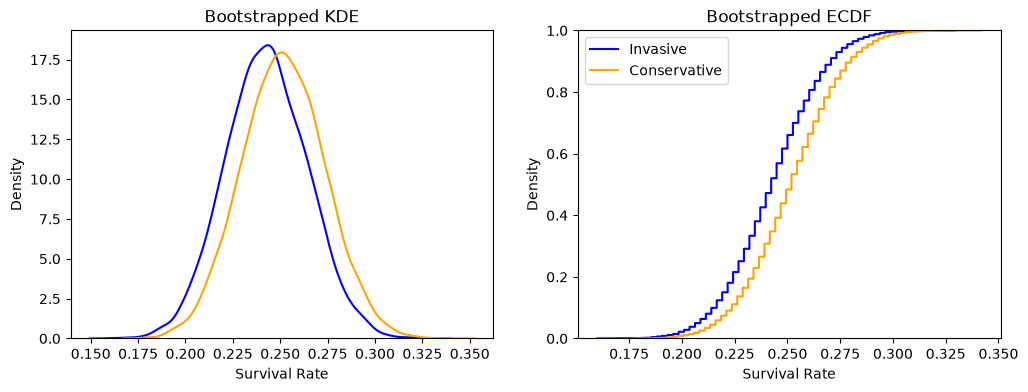

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(outcome_a, label='Invasive', color='blue', ax=ax[0])
sns.kdeplot(outcome_b, label='Conservative', color='orange', ax=ax[0]).set(title='Bootstrapped KDE', xlabel='Survival Rate', ylabel='Density')

sns.ecdfplot(outcome_a, label='Invasive', color='blue', ax=ax[1])
sns.ecdfplot(outcome_b, label='Conservative', color='orange', ax=ax[1]).set(title='Bootstrapped ECDF', xlabel='Survival Rate', ylabel='Density')

plt.legend()
plt.show()

- I see that the survival rate for conservative treatment in ~slightly~ higher. The ECDF shows us that this trend by having the conservative line more to the right, thus leading to a higher survival rate. However, it is worth noting that the outcomes are very similar and that the shapes of the ECDF and the KDE are both similar. 

**4.** Make a plot of the KDE and ECDF for the ATE. Does it have a roughly bell shape? What range of values are possible for this intervention?

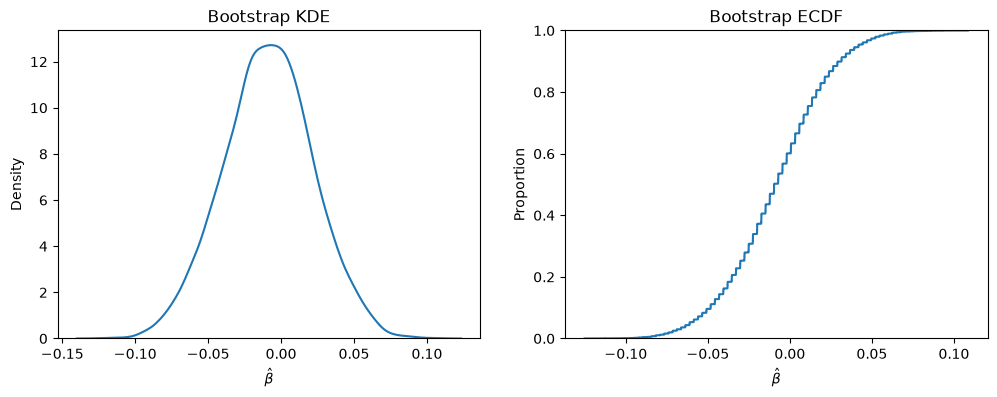

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])
ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")

## ECDF
sns.ecdfplot(ate, ax=ax[1])
ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")

plt.show()


- Yes, the KDE roughly has a bell curve shape.
- The range of values is [-0.13, 0.10]
- Because we have 0 in our range of values we are unlikely to reach a difinitive conclusion that this intervention results in a positive/negative impact.

**5.** Compute 90%, 95%, and 99% confidence intervals for the ATE. Is zero in those intervals? For which do we "fail to reject the null hypothesis that the effect size is zero" and for which do we "reject the null hypothesis that the effect size is zero"?

In [7]:
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

print(f"90% CI: {ci90}")
print(f"95% CI: {ci95}")
print(f"99% CI: {ci99}")

90% CI: [-0.06110699  0.04182016]
95% CI: [-0.07137651  0.05208322]
99% CI: [-0.08690016  0.0675536 ]


0 is in all of the intervals. Since all of the intervals contain negative, zero (most importantly), and positive values we will fail to reject the null hypothesis.

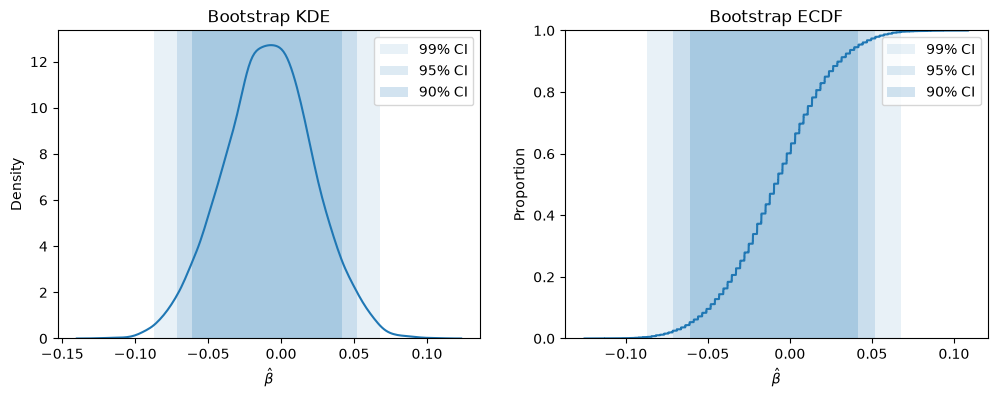

In [8]:
# Percentile bootstrap confidence intervals
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])

ax[0].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[0].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[0].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")
ax[0].legend()

## ECDF
sns.ecdfplot(ate, ax=ax[1])

ax[1].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[1].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[1].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")
ax[1].legend()

**6.** What have we learned about inserting balloons into hearts?

We are unable to deduce a positive or negative effect from inserting balloons into hearts therfore we should probablly refrain from performing an invasive procedure without conclusive evidence that the procedure results in a positive effect.

# Part 2

In `./data/diabetes.csv`, there is data from a clinical trial considering three treatments for pre-diabetics to reduce the progression to full diabetes: metformin, rosiglitazone, and lifestyle adjustments (diet, exercise). Unlike Part 1, there aren't two treatment arms (i.e. A = aortic balloon, B = no aortic balloon), but three (met, rosi, lifestyle).

You are a data analyst working for `clinicaltrials.gov` and the FDA to provide an unbiased review of the trial's results. The researchers have provided you with `./data/diabests.csv`.

In an ipynb or py file:

1. Load the `./data/diabetes.csv` data. Cross tabulate the outcomes for the three groups. What are the average outcomes for the three groups? 
2. Bootstrap the outcomes for the three groups 10,000 times. Store all of these estimates. As this is another randomized controlled trial, do the resampling within the arms. 
3. Plot the three densities on one plot and three distributions on another. Describe any patterns you see.
4. There are three treatment effects: met versus rosi, met versus lifestyle, rosi versus lifestyle. Make KDE and ECDF plots of all these comparisons.
5. Compute confidence intervals for each pairwise ATE based on its ECDF (percentile bootstrap). Do you find any statistically significant differences between the interventions? Which seems the most effective?

Then:

6. Write a short report (3-5 paragraphs) that summarizes the evidence from the trial for adopting each of the interventions or not. Use tables and visualizations. Write in a professional tone for a technical audience, and focus on evidence (or the lack thereof). Do not assume anyone has read your work in your notebooks.

In [9]:
df_d = pd.read_csv('./data/diabetes.csv')
df_d.head(10)

## Crosstabs, average treatment effect:
df_d['success'] = (df_d['outcome'] == 'success').astype(int)
print(pd.crosstab(df_d['treatment'], df_d['outcome']))
print(df_d.groupby('treatment')['success'].mean())



outcome    failure  success
treatment                  
lifestyle      109      125
met            120      112
rosi            90      143
treatment
lifestyle    0.534188
met          0.482759
rosi         0.613734
Name: success, dtype: float64


- The average outcome for lifestyle is 0.534188
- The average outcome for met is 0.482759
- The average outcome for rosi is 0.613734

In [11]:
## Bootstrapping:
R = 10_000

df_life = df_d.loc[ df_d['treatment'] == 'lifestyle',:]
df_met  = df_d.loc[ df_d['treatment'] == 'met',:]
df_rosi = df_d.loc[ df_d['treatment'] == 'rosi',:]

outcome_l = []
outcome_m = []
outcome_r = []
ate_met_rosi  = []
ate_met_life  = []
ate_rosi_life = []

for t in range(R):
    ## Resample within each arm:
    df_lt = df_life.sample(frac=1.0, replace=True)
    df_mt = df_met.sample(frac=1.0, replace=True)
    df_rt = df_rosi.sample(frac=1.0, replace=True)

    ## Evaluate outcomes:
    olt = df_lt['success'].mean() # Mean outcome for lifestyle
    omt = df_mt['success'].mean() # Mean outcome for met
    ort = df_rt['success'].mean() # Mean outcome for rosi

    ## Store results:
    outcome_l.append(olt)
    outcome_m.append(omt)
    outcome_r.append(ort)
    ate_met_rosi.append(omt - ort)
    ate_met_life.append(omt - olt)
    ate_rosi_life.append(ort - olt)

pd.Series(ate_met_rosi).describe()  # count, mean, std, min, quartiles, max


count    10000.000000
mean        -0.130460
std          0.046128
min         -0.333266
25%         -0.161092
50%         -0.130938
75%         -0.100747
max          0.032411
dtype: float64

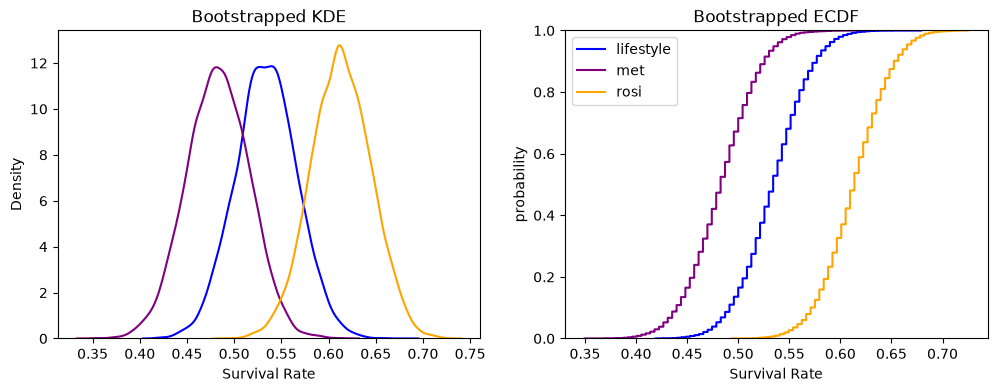

In [22]:
#3
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(outcome_l, label='lifestyle', color='blue', ax=ax[0])
sns.kdeplot(outcome_m, label='met', color='purple', ax=ax[0])
sns.kdeplot(outcome_r, label='rosi', color='orange', ax=ax[0]).set(title='Bootstrapped KDE', xlabel='Survival Rate', ylabel='Density')

sns.ecdfplot(outcome_l, label='lifestyle', color='blue', ax=ax[1])
sns.ecdfplot(outcome_m, label= 'met', color = 'purple', ax = ax[1])
sns.ecdfplot(outcome_r, label='rosi', color='orange', ax=ax[1]).set(title='Bootstrapped ECDF', xlabel='Survival Rate', ylabel='probability')

plt.legend()
plt.show()

- The success rate for rosi is the highest, followed by lifestyle, and then met.
- We see this in both the KDE and the ECDF with rosi being the rightward most curve. Specifically, for the KDE we see that rosi has the highest density of probability over 0.625, lifestyle has the highest density of probability over 0.55, and met has the highest densities of probability over 0.475
- Met and Rosi do not overlap by much 

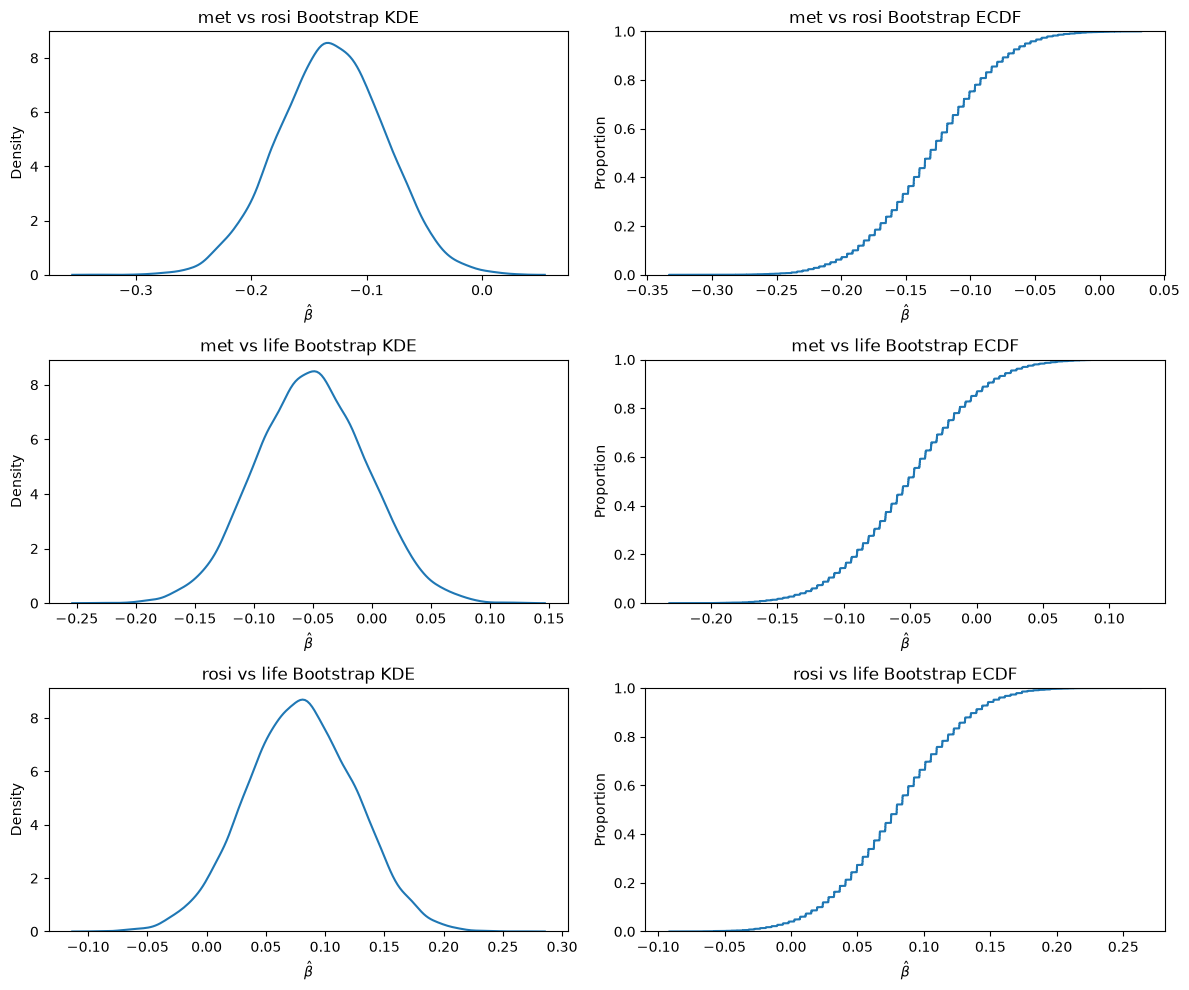

In [17]:
#4
fig, ax = plt.subplots(3, 2, figsize=(12, 10))

## met vs rosi
sns.kdeplot(ate_met_rosi, ax=ax[0,0])
ax[0,0].set_xlabel(r"$\hat{\beta}$")
ax[0,0].set_title("met vs rosi Bootstrap KDE")

## ECDF of met vs rosi
sns.ecdfplot(ate_met_rosi, ax=ax[0,1])
ax[0, 1].set_xlabel(r"$\hat{\beta}$")
ax[0, 1].set_title("met vs rosi Bootstrap ECDF")

## KDE of met vs life
sns.kdeplot(ate_met_life, ax=ax[1,0])
ax[1, 0].set_xlabel(r"$\hat{\beta}$")
ax[1, 0].set_title("met vs life Bootstrap KDE")

## ECDF of met vs life
sns.ecdfplot(ate_met_life, ax=ax[1,1])
ax[1,1].set_xlabel(r"$\hat{\beta}$")
ax[1,1].set_title("met vs life Bootstrap ECDF")

## KDE
sns.kdeplot(ate_rosi_life, ax=ax[2,0])
ax[2,0].set_xlabel(r"$\hat{\beta}$")
ax[2,0].set_title("rosi vs life Bootstrap KDE")

## ECDF
sns.ecdfplot(ate_rosi_life, ax=ax[2,1])
ax[2,1].set_xlabel(r"$\hat{\beta}$")
ax[2,1].set_title("rosi vs life Bootstrap ECDF")

plt.tight_layout()
plt.show()




5. Compute confidence intervals for each pairwise ATE based on its ECDF (percentile bootstrap). Do you find any statistically significant differences between the interventions? Which seems the most effective?

In [21]:
amr_ci90 = np.quantile(ate_met_rosi, [.05, .95])
amr_ci95 = np.quantile(ate_met_rosi, [.025, .975])
amr_ci99 = np.quantile(ate_met_rosi, [.005, .995])

aml_ci90 = np.quantile(ate_met_life, [.05, .95])
aml_ci95 = np.quantile(ate_met_life, [.025, .975])
aml_ci99 = np.quantile(ate_met_life, [.005, .995])

arl_ci90 = np.quantile(ate_rosi_life, [.05, .95])
arl_ci95 = np.quantile(ate_rosi_life, [.025, .975])
arl_ci99 = np.quantile(ate_rosi_life, [.005, .995])

print(f"90% CI for met minus rosi: {amr_ci90}")
print(f"95% CI for met minus rosi: {amr_ci95}")
print(f"99% CI for met minus rosi: {amr_ci99}")

print(f"90% CI for met minus life: {aml_ci90}")
print(f"95% CI for met minus life: {aml_ci95}")
print(f"99% CI for met minus life: {aml_ci99}")

print(f"90% CI for rosi minus life: {arl_ci90}")
print(f"95% CI for rosi minus life: {arl_ci95}")
print(f"99% CI for rosi minus life: {arl_ci99}")

90% CI for met minus rosi: [-0.2083025  -0.05767722]
95% CI for met minus rosi: [-0.22134499 -0.04069807]
99% CI for met minus rosi: [-0.24720679 -0.01065552]
90% CI for met minus life: [-0.12463159  0.02582523]
95% CI for met minus life: [-0.14154141  0.03890455]
99% CI for met minus life: [-0.1675886   0.06878187]
90% CI for rosi minus life: [0.0065845  0.15243388]
95% CI for rosi minus life: [-0.01039947  0.16943619]
99% CI for rosi minus life: [-0.03611386  0.19515067]


- Met minus Rosi is signficant at every CI (90, 95, and 99). This is because all of the confidence intervals do not contain 0 and only spans negative values. This means that at all confidence intervals rosi prevents diabetes at a rate of 20 to 5 percentage points.
- Rosi minus Lifestyle at 90% CI is significant. This is because the CI does not contain 0 and only spans positive values. This means that at a 90% CI rosi prevents diabetes at a rate of .6% to 15% more than lifestyle. However at greater CI we are unable to continue to make that assertion.
- The results of met minus lifestyle show their CI span 0 in their intervals and thus are not sgnificant. With more data maybe we could reach different conclusions. Regardless, life

Rosi seems to be the most effective treatment when compared to met and lifestyle. 